# 05 | Channel-resolved LaBraM embeddings

The model processes channels jointly. A vector labeled for one electrode can include information from other electrodes.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [3]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Channel embeddings

Select 32 evenly spaced two-second epochs per participant. Resample from 500 to 200 Hz and divide amplitudes by 100. The source recordings do not specify a physical unit. Average the two time tokens for each electrode and take the median over epochs. Preserve input channel order and align outputs by name. Archive mode reads saved vectors from the inputs directory. Extract mode uses PyTorch and compares against the archive when available.


In [4]:
assert len(ids)==19, 'Run notebook 01 first.'
label='labram'
source_file=cache/'EEG_channel_embeddings_MCMI.xlsx'
vector_path=work/(label+'_vectors.npz')
mode='auto'  # @param ["auto","extract","archive"]
def load_sheet(path,sheet):
    table=pd.read_excel(path,sheet_name=sheet)
    dimensions=[k for k in table if isinstance(k,int)]
    table=table.set_index(['subject','channel'],verify_integrity=True)
    ordered=table.loc[pd.MultiIndex.from_product([ids,channels]),dimensions].to_numpy()
    return ordered.reshape(len(ids),len(channels),len(dimensions))

if mode=='archive' or (mode=='auto' and not vector_path.exists() and source_file.exists()):
    vectors=load_sheet(source_file,'LaBraM_vectors')
elif mode=='auto' and vector_path.exists():
    with np.load(vector_path) as z:
        assert list(z['ids'])==ids and list(z['channels'])==channels
        vectors=z['vectors']
else:
    import subprocess,sys
    from importlib.util import find_spec
    if find_spec('braindecode') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','braindecode[hub]==1.4.0'])
    import torch,braindecode
    from braindecode.models import Labram,CBraMod
    from huggingface_hub import HfApi,hf_hub_download
    from scipy.signal import resample_poly
    import hashlib
    repo='braindecode/'+label+'-pretrained'
    revision=HfApi().model_info(repo).sha
    weight_path=hf_hub_download(repo,'model.safetensors',revision=revision)
    with open(weight_path,'rb') as stream:
        digest=hashlib.file_digest(stream,'sha256').hexdigest()
    if label=='labram' and digest!='53b752edb366fd6395dd3cb7d63ae3e1e16aabed040aa0901d64ef32e8f444f8':
        raise RuntimeError('LaBraM checkpoint differs from the historical analysis. Use the checkpoint matching the recorded SHA-256.')
    device='cuda' if torch.cuda.is_available() else 'cpu'
    network=(Labram if label=='labram' else CBraMod).from_pretrained(repo,revision=revision).to(device).eval()
    def labram_window_tokens(model, signal, names):
        # Match spatial positions by name and use only the temporal positions
        # present in this window. The checkpoint retains all learned positions.
        mask, positions = model._get_channel_indices(names)
        if not bool(mask.all()) or not model.neural_tokenizer:
            raise ValueError("Expected the LaBraM tokenizer and 19 recognized channels.")
        batch_size, channel_count, samples = signal.shape
        patch_count, leftover = divmod(samples, model.patch_size)
        if leftover or patch_count < 1 or patch_count >= model.temporal_embedding.shape[1]:
            raise ValueError("Unsupported LaBraM window length.")
        patches = model.patch_embed(signal).reshape(batch_size, channel_count, patch_count, model.embed_dim)
        positions = positions.to(signal.device) + 1
        spatial = model.position_embedding[:, positions, None, :]
        temporal = model.temporal_embedding[:, None, 1:patch_count + 1, :]
        sequence = (patches + spatial + temporal).flatten(1, 2)
        cls_token = model.cls_token + model.position_embedding[:, :1, :]
        sequence = model.pos_drop(torch.cat([cls_token.expand(batch_size, -1, -1), sequence], dim=1))
        for block in model.blocks:
            sequence = block(sequence)
        sequence = model.norm(sequence)
        if model.fc_norm is not None:
            sequence = model.fc_norm(sequence)
        return sequence[:, 1:].reshape(batch_size, channel_count, patch_count, model.embed_dim), sequence[:, 0]

    data_vectors=[];global_vectors=[]
    for sid in ids:
        with np.load(work/'out'/(sid+'.npz')) as record:
            original=[c.split('-')[0] for c in record['channels']]
            assert len(original)==19 and set(original)==set(channels)
            selection=np.linspace(0,len(record['eeg'])-1,32,dtype=int)
            assert len(set(selection))==32
            x=resample_poly(record['eeg'][selection].astype('float32'),2,5,axis=-1)/100
        tokens=[];cls=[]
        with torch.inference_mode():
            for batch in np.array_split(x,4):
                xb=torch.as_tensor(batch,device=device)
                if label=='labram':
                    t, cls_batch = labram_window_tokens(network, xb, original)
                    cls.extend(cls_batch.cpu().numpy())
                else:
                    t=network.encoder(network.patch_embedding(network.rearrange(xb)))
                assert tuple(t.shape)==(len(xb),19,2,200)
                tokens.extend(t.mean(2).cpu().numpy())
        data_vectors.append(np.median(tokens,axis=0)[[original.index(c) for c in channels]])
        if cls:global_vectors.append(np.median(cls,axis=0))
    vectors=np.stack(data_vectors)
    if global_vectors:np.save(work/'labram_cls.npy',global_vectors)
    (work/(label+'_model.json')).write_text(json.dumps({'repo':repo,'revision':revision,'sha256':digest,'braindecode':braindecode.__version__}))

assert vectors.shape==(19,19,200) and np.isfinite(vectors).all()
np.savez_compressed(vector_path,ids=ids,channels=channels,vectors=vectors)
if source_file.exists():
    old=load_sheet(source_file,'LaBraM_vectors')
    print('maximum absolute difference vs archive:',np.abs(vectors-old).max())

## Associations and prediction

Test PC1 correlation, distance association, and leave-one-participant-out ridge prediction. Use 10,000 participant-level permutations and correct 1,083 comparisons per metric. The historical LaBraM analysis corrected across 2,166 tests from two sources, so its adjusted results can differ.


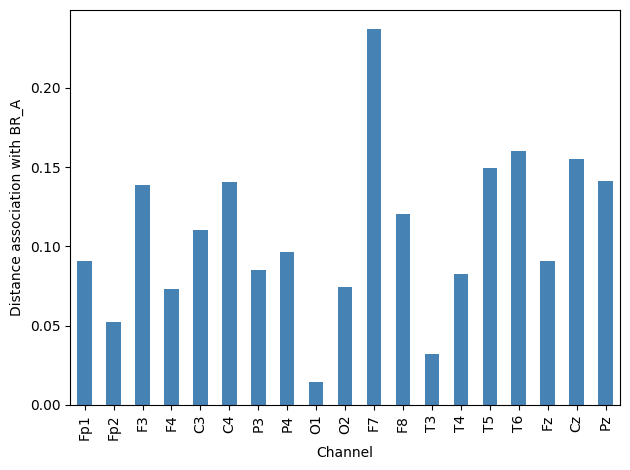

,Source,Channel,MCMI,Metric,Estimate,p_raw,q_BH,p_max,PC1_explained
3177,labram,Cz,BR_P,LOO Q2,0.362498,0.002300,0.998400,0.800720,0.305411
3120,labram,Fz,BR_P,LOO Q2,0.335276,0.002300,0.998400,0.888311,0.295764
2430,labram,C3,BR_6B,LOO Q2,0.216310,0.010199,0.998400,0.999200,0.308851
2436,labram,C3,BR_P,LOO Q2,0.262983,0.014099,0.998400,0.990001,0.308851
1696,labram,F7,BR_A,Distance association,0.237337,0.017098,0.998857,0.779922,0.395452


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.stats import rankdata,false_discovery_control
from sklearn.decomposition import PCA

def unit(a):
    return a/np.maximum(np.linalg.norm(a,axis=0),1e-20)
def centered(a):
    return unit(a-a.mean(axis=0))
def ucenter(a):
    n=len(a)
    s=a.sum(0)
    a=a-(s[:,None]+s)/(n-2)+s.sum()/((n-1)*(n-2))
    np.fill_diagonal(a,0)
    return a/max(np.linalg.norm(a),1e-20)
def channel_tests(V,ch,df,label):
    Y=df.to_numpy(float); n=len(Y); rank=rankdata(Y,axis=0); R=centered(rank)
    A=[]; D=[]; H=[]; exp=[]
    for x in V.transpose(1,0,2).astype(float):
        p=PCA(n_components=1,svd_solver='full').fit(x); A.append(centered(rankdata(p.transform(x)[:,0])));exp.append(p.explained_variance_ratio_[0])
        D.append(ucenter(cdist(x,x)).ravel())
        pred=np.zeros((n,n))
        for i in range(n):
            j=np.arange(n)!=i
            z=(x-x[j].mean(0))/np.where(x[j].std(0)>0,x[j].std(0),1)
            K=z@z.T/x.shape[1]
            w=np.linalg.solve(K[j][:,j]+np.eye(n-1),K[i,j])
            pred[i,j]=w+(1-w.sum())/(n-1)
        E=np.eye(n)-pred; H.append((E.T@E).ravel())
    A,D,H=map(np.asarray,(A,D,H))
    Z=np.stack([ucenter(cdist(v[:,None],v[:,None])) for v in rank.T],axis=-1)
    yc=Y-Y.mean(0); denom=(yc**2).sum(0)*(n/(n-1))**2
    Q=yc[:,None,:]*yc[None,:,:]/denom
    rng=np.random.default_rng(42); perms=np.stack([np.arange(n)]+[rng.permutation(n) for _ in range(10000)])
    def calc(P):
        b=len(P)
        def mul(M,t):
            return (M@t.swapaxes(0,1).reshape(M.shape[1],-1)).reshape(19,b,-1).transpose(1,0,2)
        def pairs(t):
            return t[P[:,:,None],P[:,None,:]].reshape(b,n*n,-1)
        return [mul(A,R[P]),mul(D,pairs(Z)),1-mul(H,pairs(Q))]
    obs=[m[0] for m in calc(perms[:1])]
    target=[abs(obs[0]),*obs[1:]]; hit=np.ones((3,19,57)); mx=hit.copy()
    for batch in np.array_split(perms[1:],200):
        for k,m in enumerate(calc(batch)):
            if k==0:m=abs(m)
            hit[k]+=(m>=target[k]-1e-12).sum(0)
            mx[k]+=(m.max((1,2))[:,None,None]>=target[k]-1e-12).sum(0)
    rows=[]
    for k,name in enumerate(['Spearman PC1','Distance association','LOO Q2']):
        pv=hit[k]/len(perms); q=false_discovery_control(pv.ravel()).reshape(pv.shape)
        for c,channel in enumerate(ch):
            for t,score in enumerate(df):
                rows.append([label,channel,score,name,obs[k][c,t],pv[c,t],q[c,t],mx[k,c,t]/len(perms),exp[c]])
    return pd.DataFrame(rows,columns=['Source','Channel','MCMI','Metric','Estimate','p_raw','q_BH','p_max','PC1_explained'])

scales=scores.loc[ids,[c for c in scores if c.startswith(('BR_','RAW_')) or c.endswith('_Score')]]
scales=scales.loc[:,scales.nunique()>1]
results=channel_tests(vectors,channels,scales,label)
results.to_csv(work/(label+'_tests.csv'),index=False)
part=results.query("MCMI=='BR_A' and Metric=='Distance association'").set_index('Channel').loc[channels]
part.Estimate.plot.bar(color='steelblue');plt.ylabel('Distance association with BR_A');figure(label+'_anxiety')
display(results.sort_values('p_raw').head())

## Global embedding and clinical profile

Use the CLS token to represent the whole recording. Calculate prediction Q² against the training mean. Run notebook 04 first to also evaluate the combination of delta and CLS features.


In [6]:
def loo_predictions(inputs, targets):
    n=len(targets); predictions=np.zeros_like(targets,dtype=float)
    for i in range(n):
        tr=np.arange(n)!=i; kernels=[]
        for x in inputs:
            std=x[tr].std(0); z=(x-x[tr].mean(0))/np.where(std>0,std,1)
            kernels.append(z@z.T/z.shape[1])
        k=np.mean(kernels,axis=0)
        predictions[i]=targets[tr].mean(0)+k[i,tr]@np.linalg.solve(k[tr][:,tr]+np.eye(n-1),targets[tr]-targets[tr].mean(0))
    return predictions
if label=='labram':
    if (work/'labram_cls.npy').exists():
        cls=np.load(work/'labram_cls.npy')
    elif (cache/'EEG_foundation_MCMI.xlsx').exists():
        cls=pd.read_excel(cache/'EEG_foundation_MCMI.xlsx',sheet_name='labram',index_col=0).loc[ids].to_numpy()
    else:
        cls=None
    if cls is not None:
        inputs={'labram':[cls]}
        if (work/'direct_features.csv').exists():
            delta=pd.read_csv(work/'direct_features.csv',index_col=0).loc[ids,['LogDelta']].to_numpy()
            inputs.update(delta=[delta],labram_plus_delta=[cls,delta])
        target=scales.to_numpy(); n=len(target); baseline=(target.sum(0)-target)/(n-1)
        for key,matrices in inputs.items():
            prediction=loo_predictions(matrices,target)
            q2=1-((target-prediction)**2).sum(0)/((target-baseline)**2).sum(0)
            pd.Series(q2,index=scales.columns).to_csv(work/('profile_'+key+'.csv'))
            print(key,'mean clinical Q2',np.mean([v for c,v in zip(scales,q2) if c.startswith('BR_') and c not in ['BR_X','BR_Y','BR_Z']]))

labram mean clinical Q2 -0.06288391499156826
delta mean clinical Q2 -0.06236523615915577
labram_plus_delta mean clinical Q2 -0.10767154048591676
